In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data Analysis and Visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_ImadolLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,temperature,25.389999,c,2025-11-06 12:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,12:45:00
1,6121047,Imadol(SC-27)- GD Labs,temperature,30.306500,c,2025-11-06 13:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,13:45:00
2,6121047,Imadol(SC-27)- GD Labs,temperature,31.118750,c,2025-11-06 14:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,14:45:00
3,6121047,Imadol(SC-27)- GD Labs,temperature,29.722958,c,2025-11-06 15:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,15:45:00
4,6121047,Imadol(SC-27)- GD Labs,temperature,27.721125,c,2025-11-06 16:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,16:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6121047,Imadol(SC-27)- GD Labs,temperature,20.600000,c,2026-02-26 17:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,17:45:00
996,6121047,Imadol(SC-27)- GD Labs,temperature,20.200000,c,2026-02-26 18:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,18:45:00
997,6121047,Imadol(SC-27)- GD Labs,temperature,19.900000,c,2026-02-26 19:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,19:45:00
998,6121047,Imadol(SC-27)- GD Labs,temperature,19.800000,c,2026-02-26 20:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,20:45:00


In [3]:
df365.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

In [4]:
# Convert the date column to a proper datetime value
df365["date"] = pd.to_datetime(df365["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df365.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

In [5]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2025-11-06,6121047,Imadol(SC-27)- GD Labs,temperature,25.984856,c,12,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
1,2025-11-07,6121047,Imadol(SC-27)- GD Labs,temperature,24.603138,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
2,2025-11-08,6121047,Imadol(SC-27)- GD Labs,temperature,24.054232,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
3,2025-11-09,6121047,Imadol(SC-27)- GD Labs,temperature,23.547172,c,14,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
4,2025-11-10,6121047,Imadol(SC-27)- GD Labs,temperature,24.762690,c,18,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
5,2025-11-11,6121047,Imadol(SC-27)- GD Labs,temperature,23.155113,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
6,2025-11-12,6121047,Imadol(SC-27)- GD Labs,temperature,20.910846,c,18,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
7,2025-11-13,6121047,Imadol(SC-27)- GD Labs,temperature,22.038181,c,23,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
8,2025-11-14,6121047,Imadol(SC-27)- GD Labs,temperature,20.626544,c,15,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
9,2025-11-15,6121047,Imadol(SC-27)- GD Labs,temperature,21.821122,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_22814/1693882114.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


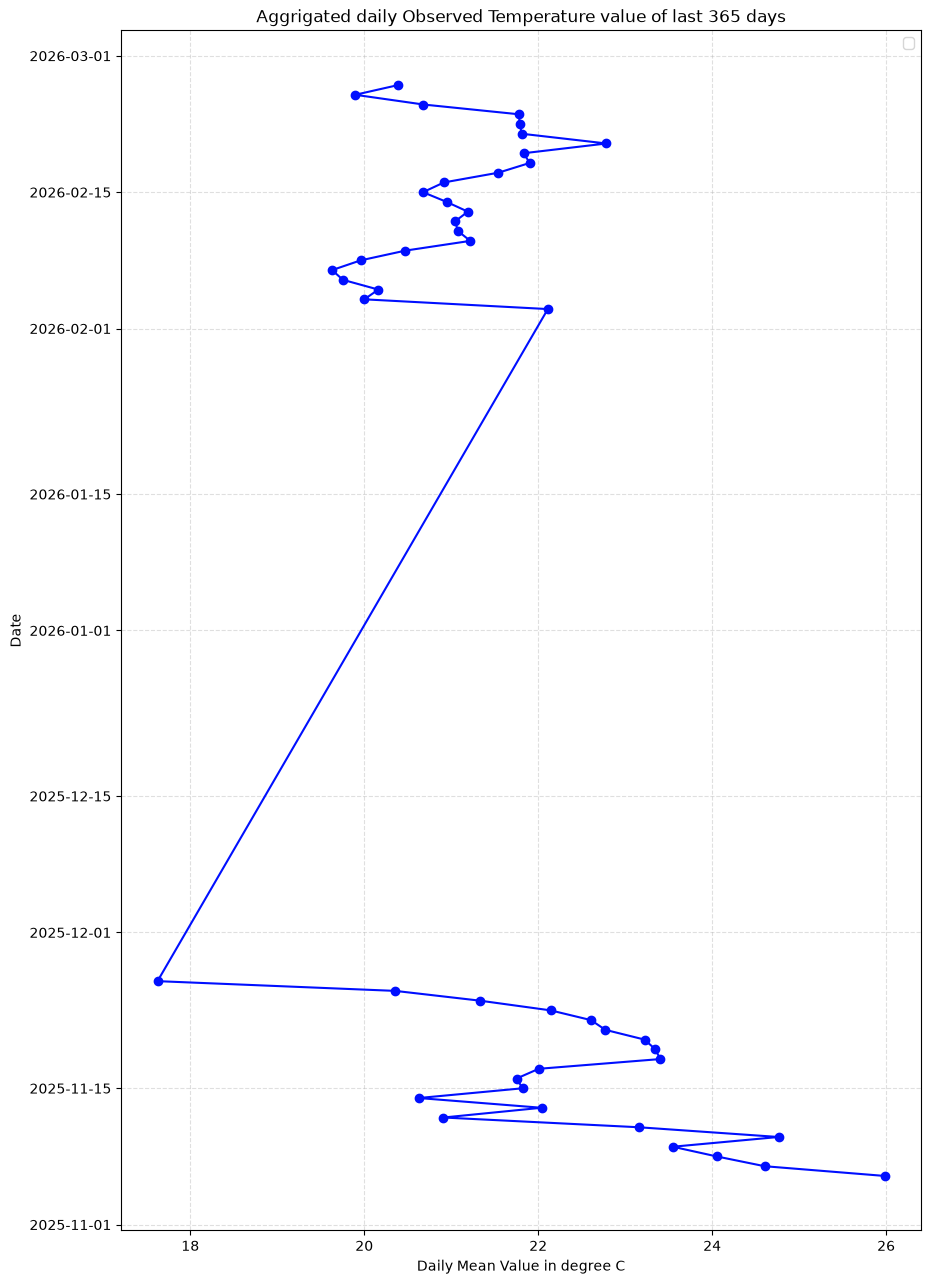

In [6]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 365 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 37 days

In [7]:
df30 = pd.read_csv('cleaned_ImadolLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,temperature,25.9,c,2026-09-05 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,temperature,26.3,c,2026-09-05 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,temperature,27.6,c,2026-09-05 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,temperature,29.4,c,2026-09-05 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,temperature,30.3,c,2026-09-05 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
879,6121047,Imadol(SC-27)- GD Labs,temperature,23.2,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
880,6121047,Imadol(SC-27)- GD Labs,temperature,23.1,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
881,6121047,Imadol(SC-27)- GD Labs,temperature,22.7,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
882,6121047,Imadol(SC-27)- GD Labs,temperature,22.1,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [8]:
df30.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

In [9]:
# Convert the date column to a proper datetime value
df30["date"] = pd.to_datetime(df30["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df30.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

In [10]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-09-05,6121047,Imadol(SC-27)- GD Labs,temperature,26.972222,c,18,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
1,2026-09-06,6121047,Imadol(SC-27)- GD Labs,temperature,26.904167,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
2,2026-09-07,6121047,Imadol(SC-27)- GD Labs,temperature,27.695833,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
3,2026-09-08,6121047,Imadol(SC-27)- GD Labs,temperature,28.641667,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
4,2026-09-09,6121047,Imadol(SC-27)- GD Labs,temperature,28.179167,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
5,2026-09-10,6121047,Imadol(SC-27)- GD Labs,temperature,28.116667,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
6,2026-09-11,6121047,Imadol(SC-27)- GD Labs,temperature,27.720833,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
7,2026-09-12,6121047,Imadol(SC-27)- GD Labs,temperature,27.912500,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
8,2026-09-13,6121047,Imadol(SC-27)- GD Labs,temperature,27.795833,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
9,2026-09-14,6121047,Imadol(SC-27)- GD Labs,temperature,27.800000,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_22814/474956342.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


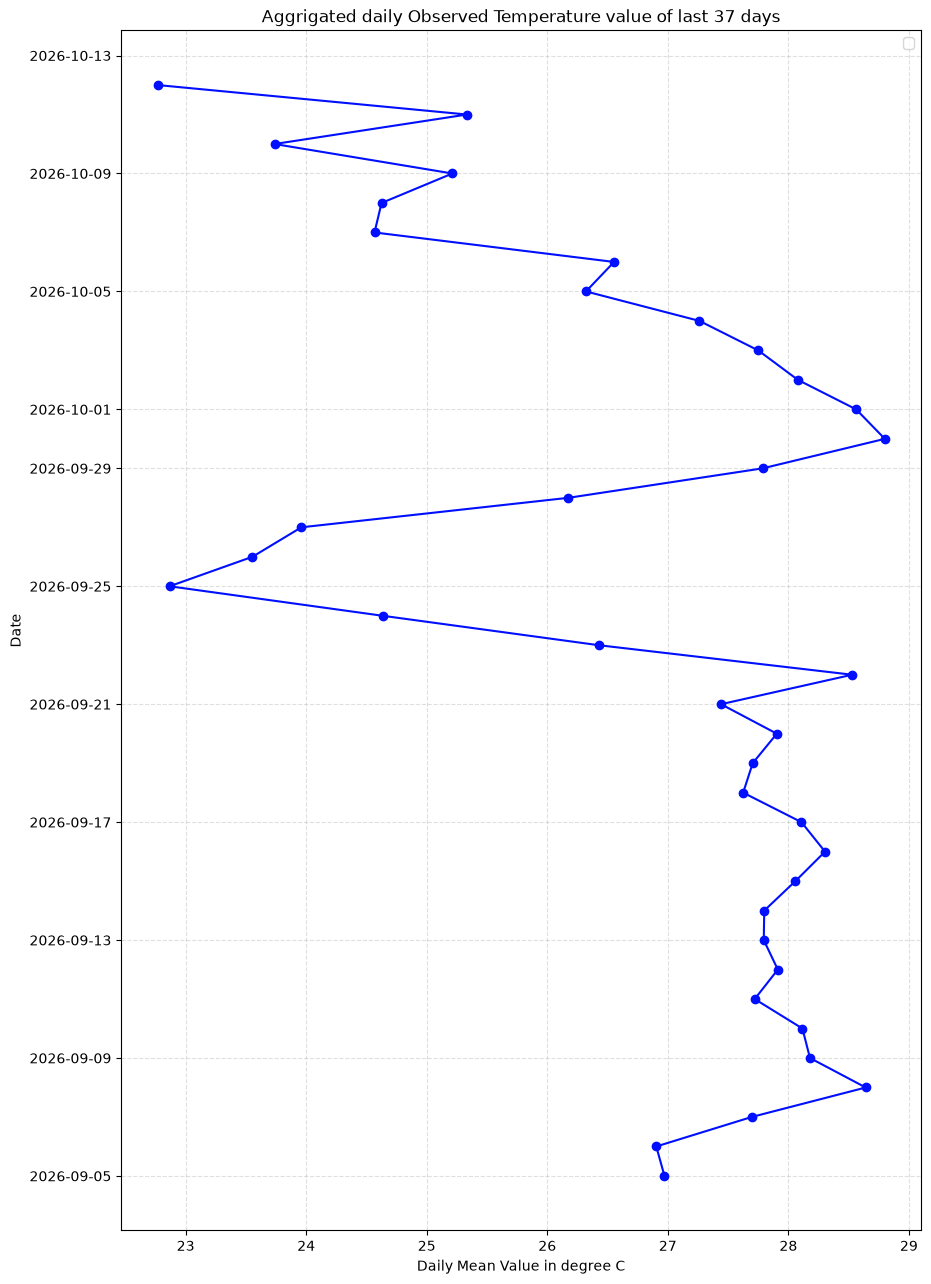

In [12]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 37 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 1 week

In [13]:
df7 = pd.read_csv('cleaned_ImadolLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,temperature,24.3,c,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,temperature,24.7,c,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,temperature,26.5,c,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,temperature,28.2,c,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,temperature,29.2,c,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6121047,Imadol(SC-27)- GD Labs,temperature,23.2,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,6121047,Imadol(SC-27)- GD Labs,temperature,23.1,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,6121047,Imadol(SC-27)- GD Labs,temperature,22.7,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,6121047,Imadol(SC-27)- GD Labs,temperature,22.1,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [14]:
# Convert the date column to a proper datetime value
df7["date"] = pd.to_datetime(df7["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df7.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]


In [15]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-10-05,6121047,Imadol(SC-27)- GD Labs,temperature,26.844444,c,18,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
1,2026-10-06,6121047,Imadol(SC-27)- GD Labs,temperature,26.554167,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
2,2026-10-07,6121047,Imadol(SC-27)- GD Labs,temperature,24.566667,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
3,2026-10-08,6121047,Imadol(SC-27)- GD Labs,temperature,24.625000,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
4,2026-10-09,6121047,Imadol(SC-27)- GD Labs,temperature,25.212500,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
5,2026-10-10,6121047,Imadol(SC-27)- GD Labs,temperature,23.737500,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
6,2026-10-11,6121047,Imadol(SC-27)- GD Labs,temperature,25.333333,c,24,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient
7,2026-10-12,6121047,Imadol(SC-27)- GD Labs,temperature,22.766667,c,6,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_22814/3647158116.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


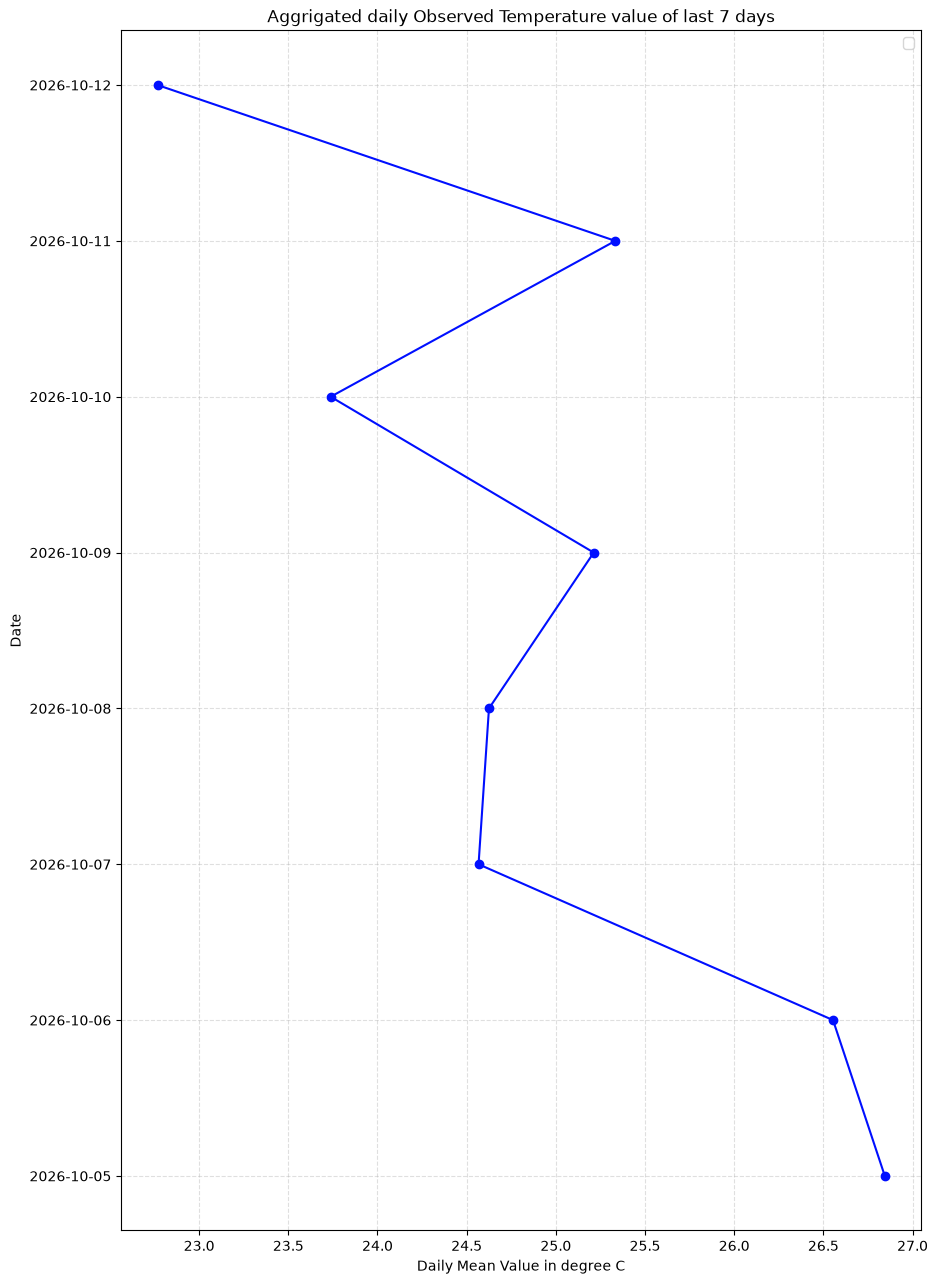

In [16]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 7 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [17]:
df24 = pd.read_csv('cleaned_ImadolLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,temperature,21.9,c,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,temperature,22.2,c,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,temperature,23.8,c,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,temperature,26.2,c,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,temperature,28.0,c,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6121047,Imadol(SC-27)- GD Labs,temperature,30.0,c,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6121047,Imadol(SC-27)- GD Labs,temperature,31.2,c,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6121047,Imadol(SC-27)- GD Labs,temperature,29.7,c,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6121047,Imadol(SC-27)- GD Labs,temperature,29.9,c,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6121047,Imadol(SC-27)- GD Labs,temperature,29.9,c,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


In [18]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_22814/318776006.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


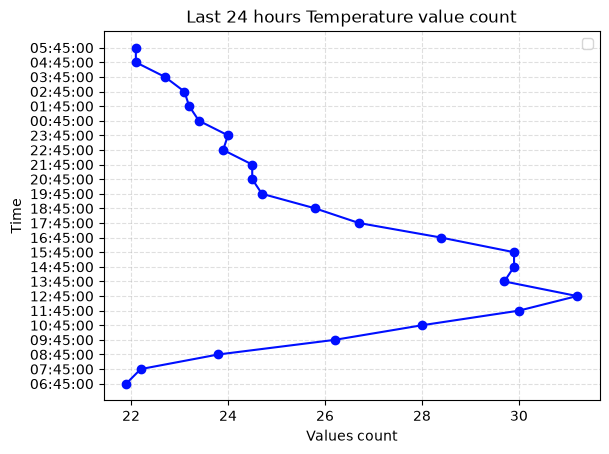

In [19]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Last 24 hours Temperature value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()